# IEEE-CIS Card ID Reconstruction

IEEE-CIS does not come with a card or customer ID, but our card-history features and card-level Precision@k all need to know which transactions belong to the same card. This notebook reconstructs a card ID for every transaction, using the columns chosen in the card ID section of `02_exploratory_analysis.ipynb`

## 1. Load the data
1. Load the transaction columns we need and sort them by time

2. Convert `TransactionDT` to whole days and calculate a reference day (`day - D`) for `D1`, `D4`, `D10` and `D15`. From notebook 02, `D1` is used to build the key, and `D4`, `D10` and `D15` are used as extra checks

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


DATA_DIR = Path("../data/raw")
INTERIM_DIR = Path("../data/interim")

# only load the columns we need (the full file has 394 columns)
columns = ["TransactionID", "isFraud", "TransactionDT", "TransactionAmt", "ProductCD",
           "card1", "card2", "card3", "card4", "card5", "card6", "addr1", "addr2", "P_emaildomain",
           "D1", "D3", "D4", "D10", "D15"]
ieee = pd.read_csv(DATA_DIR / "train_transaction.csv", usecols=columns)

# sort transactions from earliest to latest
ieee = ieee.sort_values(["TransactionDT", "TransactionID"]).reset_index(drop=True)

# convert seconds to whole days
ieee["day"] = np.floor(ieee["TransactionDT"] / 86400)

# calculate a reference day for each counter
for col in ["D1", "D4", "D10", "D15"]:
    ieee[col + "n"] = ieee["day"] - ieee[col]

print("shape:", ieee.shape)
print("days:", ieee["day"].min(), "-", ieee["day"].max())

shape: (590540, 24)
days: 1.0 - 182.0


## 2. Check existing columns
- Check the unique values, missing values and number of transactions sharing each value, to see whether the existing card and address columns could work as a card ID

- Check how often `addr1`, `D1` and `D3` are missing for each product type, since these are the 3 columns the method depends on:
  - `addr1` is part of the key. If it is missing, cards with the same `card1` and first-use day fall into one `NA` group
  - `D1` gives the first-use day (`D1n`). If it is missing, the transaction gets no card ID
  - `D3` is used to check the key (Section 4) and to refine it (Section 6). If it is missing, the transaction cannot be checked or refined

In [2]:
card_cols = ["card1", "card2", "card3", "card4", "card5", "card6", "addr1", "addr2", "P_emaildomain"]

card_summary = pd.DataFrame({
    "unique values": ieee[card_cols].nunique(),
    "missing %": ieee[card_cols].isna().mean() * 100,
    "max txns per value": [ieee[col].value_counts().max() for col in card_cols]
})

display(card_summary)

# check missing values separately for each product type
missing_by_product = (
    ieee[["addr1", "D1", "D3"]]
    .isna()
    .groupby(ieee["ProductCD"])
    .mean() * 100
)

display(missing_by_product)

,unique values,missing %,max txns per value
card1,13553,0.000000,14932
card2,500,1.512683,48935
card3,114,0.265012,521287
card4,4,0.267044,384767
card5,119,0.721204,296546
card6,4,0.266028,439938
addr1,332,11.126427,46335
addr2,74,11.126427,520481
P_emaildomain,59,15.994852,228355


,addr1,D1,D3
ProductCD,,,
C,95.037873,0.284593,60.886761
H,0.254360,0.066618,99.218750
R,0.132630,0.050399,96.737314
S,1.797386,0.000000,74.036808
W,0.055496,0.234949,32.596038


**Takeaway**

- `card1` has 13,553 unique values, with up to 14,932 transactions sharing one value. The other card columns have fewer unique values (e.g. `card4` and `card6` have 4 values each) => they create broad groups => could possibly explore combining them with other information to form a proxy card ID

- `addr1` is missing for around 95% of product C transactions but is almost always available for the other products. We retain these transactions and represent missing addresses as `NA` when building the key **BUT** this could group unrelated transactions together => check in Section 5

- `D3` is missing for almost all `H` and `R` transactions (and a third of `W`) => the D3 check will mainly cover `W`, `C` and `S` transactions, and cannot validate the groups equally across all products

## 3. Build card key using `card1 + addr1 + D1n`
`D1` looks like the number of days since the card was first used. If that is true, `D1n = day - D1` should stay the same for every transaction of the same card, so `card1 + addr1 + D1n` should separate the different cards inside a `card1 + addr1` group

1. Check an example group to see whether `D1` increases with the transaction day

2. Check whether `day` and `D1` increase at the same time. If one increases before the other, `D1n = day - D1` could change even for the same card, splitting its transactions into different groups => shift the transaction time by -12 to +12 hours and compare the number of keys (the shift with the fewest keys should be the correct one **BUT** this does not guarantee that the card groups are correct)

In [3]:
# convert addr1 and D1n to text so they can be joined: 315.0 becomes "315" and missing addr1 becomes "NA"
addr1_text = ieee["addr1"].astype("Int64").astype(str).where(ieee["addr1"].notna(), "NA")
d1n_text = ieee["D1n"].astype("Int64").astype(str)

# combine card1, addr1 and D1n
ieee["card_id_base"] = ieee["card1"].astype(str) + "_" + addr1_text + "_" + d1n_text

# leave the card ID missing when D1 is unavailable
ieee.loc[ieee["D1"].isna(), "card_id_base"] = np.nan


# 1. Example

# find a group with 8 transactions spanning more than 60 days
key_info = ieee.groupby("card_id_base")["day"].agg(["size", "min", "max"])
example_keys = key_info[(key_info["size"] == 8) & (key_info["max"] - key_info["min"] > 60)]
example = example_keys.index[0]

display(ieee.loc[ieee["card_id_base"] == example, ["TransactionID", "day", "D1", "D1n", "D3", "ProductCD", "TransactionAmt", "P_emaildomain", "isFraud"]])

,TransactionID,day,D1,D1n,D3,ProductCD,TransactionAmt,P_emaildomain,isFraud
307031,3294031,88.0,0.0,88.0,NaN,W,97.95,NaN,0
341503,3328503,97.0,9.0,88.0,9.0,W,107.95,anonymous.com,0
366704,3353704,105.0,17.0,88.0,8.0,W,87.95,anonymous.com,0
429963,3416963,125.0,37.0,88.0,20.0,W,87.95,anonymous.com,0
467614,3454614,139.0,51.0,88.0,14.0,W,87.95,anonymous.com,0
486718,3473718,146.0,58.0,88.0,7.0,W,87.95,anonymous.com,0
488390,3475390,147.0,59.0,88.0,0.0,W,82.95,anonymous.com,0
585531,3572531,181.0,93.0,88.0,34.0,W,97.95,anonymous.com,0


shift with the fewest keys: 0 hours
keys with no shift: 217020
keys with +1 hour shift: 228987
keys with -1 hour shift: 228363


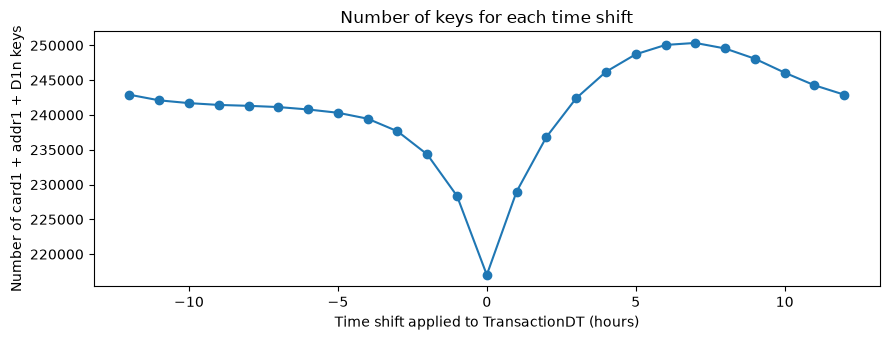

In [4]:
# 2. Day boundary

has_d1 = ieee[ieee["D1"].notna()]
card_addr = has_d1["card1"].astype(str) + "_" + addr1_text[has_d1.index]

# count the number of keys after shifting TransactionDT by each number of hours
shift_counts = {}

for hours in range(-12, 13):
    shifted_day = np.floor((has_d1["TransactionDT"] + hours * 3600) / 86400)
    shifted_key = card_addr + "_" + (shifted_day - has_d1["D1"]).astype(int).astype(str)
    shift_counts[hours] = shifted_key.nunique()

shift_counts = pd.Series(shift_counts)

print("shift with the fewest keys:", shift_counts.idxmin(), "hours")
print("keys with no shift:", shift_counts[0])
print("keys with +1 hour shift:", shift_counts[1])
print("keys with -1 hour shift:", shift_counts[-1])

plt.figure(figsize=(9, 3.5))
plt.plot(shift_counts.index, shift_counts.values, marker="o")
plt.xlabel("Time shift applied to TransactionDT (hours)")
plt.ylabel("Number of card1 + addr1 + D1n keys")
plt.title("Number of keys for each time shift")
plt.tight_layout()
plt.show()

**Takeaway**
- In the example, `D1n` is 88 for all 8 transactions. This supports `D1` being the days since the card was first used and shows how `D1n` can help group transactions across different days under the same proxy card ID

- `D3` also matches the gaps between some transactions (e.g. day 88 to day 97 is 9 days, matching `D3 = 9`). Check this for more groups in Section 4

- Using no shift (0 hours) gives the fewest keys (217,020), compared with about 229,000 after shifting by just 1 hour either way, so we keep the original day calculation

## 4. Check card key using `D3`
`D3` looks like the number of days since the card's previous transaction, and it is not used to build the key, so we compare it with the actual gap (in days) to the previous transaction with the same key:
- **consistent**: `D3` and the gap differ by at most 1 day (to allow for rounding)

- **merge error**: `D3` > gap + 1 => the previous transaction under the key is more recent than the card's real previous transaction, so the key has mixed in a different card

- **split error**: `D3` < gap - 1 => the card had a more recent transaction that ended up under a different key, so one card has been split into two keys

The first transaction of each key has no gap, and rows with missing `D3` cannot be checked, so these are left out

checkable transactions: 284351
consistent: 94.6 %
merge errors: 5.16 %
split errors: 0.24 %


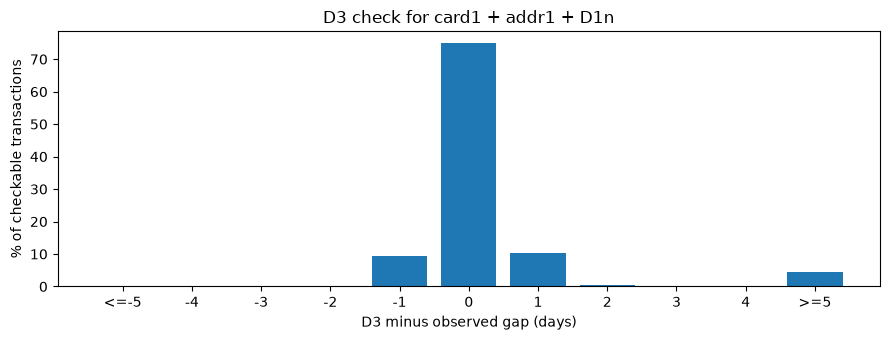

In [5]:
rows = ieee[["card_id_base", "day", "D3"]].dropna(subset=["card_id_base"])

# gap in days to the previous transaction with the same key
# (ieee is already sorted by time, so shift() gives the previous transaction of the same key)
gap = rows["day"] - rows.groupby("card_id_base")["day"].shift()

# D3 minus the gap (missing if the transaction cannot be checked)
diff = (rows["D3"] - gap).dropna()

print("checkable transactions:", len(diff))
print("consistent:", round((diff.abs() <= 1).mean() * 100, 2), "%")
print("merge errors:", round((diff > 1).mean() * 100, 2), "%")
print("split errors:", round((diff < -1).mean() * 100, 2), "%")

# plot the differences (anything beyond +-5 days is grouped together)
counts = diff.clip(-5, 5).value_counts(normalize=True).sort_index() * 100

plt.figure(figsize=(9, 3.5))
plt.bar(counts.index, counts.values)
plt.xticks(counts.index, ["<=-5", "-4", "-3", "-2", "-1", "0", "1", "2", "3", "4", ">=5"])
plt.xlabel("D3 minus observed gap (days)")
plt.ylabel("% of checkable transactions")
plt.title("D3 check for card1 + addr1 + D1n")
plt.tight_layout()
plt.show()

**Takeaway**
- 94.6% of the 284,351 checkable transactions agree with `D3`, so `card1 + addr1 + D1n` already matches the card's own transaction history very well

- Most of the remaining errors are merge errors (5.16%), and split errors are rare (0.24%). This means the key almost never breaks a card apart, but sometimes merges multiple cards with the same `card1`, `addr1` and `D1n`, so we try separating merged cards (Section 6)

## 5. Compare different keys
Compare the D3 results for different combinations of columns. Also check:
- **D4n, D10n and D15n spread**: how often these values vary by more than 1 day within a group (like `D1n`, these should mostly stay the same for one card) **BUT** they can also change for the same card (e.g. if whatever they count resets), so we only use them to compare keys and not as exact errors

- **email conflict**: how often a group contains different email domains

- **mixed labels**: how often a group contains both fraud and non-fraud transactions (note: this is just to check the keys, we never use it to build the keys)

Note: spread, email and label measures will improve automatically when keys get smaller (fewer transactions per key => less chance of a change), so a finer key will always improve these measures (see Section 6)

In [6]:
# helper function to calculate the same quality measures for each key
# (kept as a function because it is used again in Section 6.1)
def key_quality(key, name):
    rows = ieee.assign(key=key).dropna(subset=["key"])

    # D3 minus the gap to the previous transaction with the same key
    gap = rows["day"] - rows.groupby("key")["day"].shift()
    diff = (rows["D3"] - gap).dropna()

    txns_per_key = rows.groupby("key").size()

    # only keys with more than one transaction can have a spread, conflict or mixed labels
    multi = rows[rows["key"].map(txns_per_key) > 1].groupby("key")
    labels = multi["isFraud"].agg(["min", "max"])

    result = {
        "key": name,
        "number of keys": key.nunique(),
        "rows with a key %": key.notna().mean() * 100,
        "single-txn keys %": (txns_per_key == 1).mean() * 100,
        "D3 consistent %": (diff.abs() <= 1).mean() * 100,
        "D3 merge errors %": (diff > 1).mean() * 100,
        "D3 split errors %": (diff < -1).mean() * 100,
    }

    for col in ["D4n", "D10n", "D15n"]:
        spread = multi[col].max() - multi[col].min()
        result[col + " spread > 1 day %"] = (spread > 1).mean() * 100

    result["email conflict %"] = (multi["P_emaildomain"].nunique() > 1).mean() * 100
    result["mixed labels %"] = ((labels["min"] == 0) & (labels["max"] == 1)).mean() * 100

    return result


# different keys to compare

# card1 only
card1_key = ieee["card1"].astype(str)
# card1 + addr1 (no key when addr1 is missing, like the provisional key)
card1_addr1_key = ieee["card1"].astype(str) + "_" + addr1_text
card1_addr1_key[ieee["addr1"].isna()] = np.nan

# add the remaining card columns and addr2 to the base key
static_key = ieee["card_id_base"].copy()
for col in ["card2", "card3", "card4", "card5", "card6", "addr2"]:
    col_text = ieee[col].astype(str)
    if pd.api.types.is_numeric_dtype(ieee[col]):
        col_text = ieee[col].astype("Int64").astype(str)
    static_key = static_key + "_" + col_text.where(ieee[col].notna(), "NA")

# add email domain to the base key
email_key = ieee["card_id_base"] + "_" + ieee["P_emaildomain"].astype(str).where(ieee["P_emaildomain"].notna(), "NA")

comparison = pd.DataFrame([
    key_quality(card1_key, "card1"),
    key_quality(card1_addr1_key, "card1 + addr1"),
    key_quality(ieee["card_id_base"], "card1 + addr1 + D1n"),
    key_quality(static_key, "base + card2-6, addr2"),
    key_quality(email_key, "base + P_emaildomain")
]).set_index("key")

display(comparison.T)

key,card1,card1 + addr1,card1 + addr1 + D1n,"base + card2-6, addr2",base + P_emaildomain
number of keys,13553.000000,37531.000000,217020.000000,221685.000000,272922.000000
rows with a key %,100.000000,88.873573,99.785112,99.785112,99.785112
single-txn keys %,25.411348,39.482028,57.408995,57.907842,64.728750
D3 consistent %,36.301596,42.585599,94.598225,94.365308,94.212999
D3 merge errors %,63.697480,57.212831,5.160875,5.135258,1.819238
D3 split errors %,0.000925,0.201570,0.240899,0.499435,3.967763
D4n spread > 1 day %,65.248788,58.305816,25.423289,25.128601,17.133270
D10n spread > 1 day %,71.055495,64.249549,31.752334,31.326089,26.285281
D15n spread > 1 day %,68.008705,60.397129,21.420303,21.143047,15.320528
email conflict %,73.083391,62.624928,28.507752,28.140003,0.000000


**Takeaway**
- Using only `card1` or `card1 + addr1` gives low D3 consistency (36% and 43%), while `D1n` increases this to 94.6%. `card1 + addr1` also covers only 88.9% of transactions while `card1 + addr1 + D1n` covers 99.8% of transactions. `card1 + addr1 + D1n` also has fewer mixed labels than `card1` and `card1 + addr1`
    - `card1 + addr1 + D1n` is the best compared to `card1` and `card1 + addr1`

- Adding `card2` to `card6` and `addr2` barely changes anything (merge errors 5.16% -> 5.14%) but doubles the split errors (0.24% -> 0.50%). There is little benefit from adding these columns

- Adding email reduces possible merges (5.16% -> 1.82%), but increases possible splits (0.24% -> 3.97%). It also creates more single-transaction groups (57% -> 65%), so it leaves fewer transactions with card history

**Final decision**:
Keep `card1 + addr1 + D1n` as the base key **BUT** we can try using additional information to separate possible merged cards without breaking up too many existing groups (Section 6)

## 6. Refine card key using `D3`
Since `D3` likely tells us when a card's previous transaction happened, we can use each transaction's own `D3` to work out which earlier transaction in the same key it follows. Within each base key, we go through the transactions in time order and add each one to a "chain" (a sub-card). Each chain remembers the day of its latest transaction and its latest email domain

For each transaction:
1. Calculate `day - D3` to estimate when its previous transaction happened

2. If a chain's latest transaction was on that day (+-1 day), join that chain. If several match, prefer the one with a compatible email (same domain or either one missing), then the most recent one

3. If `day - D3` is before the first day in the data, the card's previous transaction is not in the data, so it cannot be any of the chains we have already seen => start a new chain

4. Otherwise, join the most recent chain with a compatible email (matching or missing email domain). If none exists, start a new chain (since both `D3` and the email disagree)

5. If `D3` is missing (about 44% of transactions, including almost all `H` and `R` and a third of `W`), join an existing chain, preferring a compatible email (matching or missing email domain). If none has a compatible email, join the most recent chain overall. Only start a new chain if no chains exist yet

The rules only use the current transaction and earlier ones (never later ones) and never use labels, so the card ID of a transaction is something that would be known at the time it is scored (tested in Section 7). The final ID is the base key + `#` + chain number (e.g. `13926_315_-13#0`)

In [7]:
# function to build the refined card IDs
def chain_card_ids(data, d3_col="D3"):
    # put each base key's transactions together, in time order
    rows = data[data["card_id_base"].notna()].sort_values(["card_id_base", "TransactionDT", "TransactionID"])

    keys = rows["card_id_base"].values
    days = rows["day"].values
    d3 = rows[d3_col].values
    emails = rows["P_emaildomain"].values
    first_day = data["day"].min()

    chain_numbers = []
    previous_key = None

    for i in range(len(rows)):
        # start with no chains for every new base key
        # each chain is [chain number, day of latest transaction, latest email]
        if keys[i] != previous_key:
            chains = []
            previous_key = keys[i]

        email = emails[i] if isinstance(emails[i], str) else None

        # chains with a compatible email (same email, or either one is missing)
        compatible = [c for c in chains if c[2] is None or email is None or c[2] == email]
        chosen = None

        if len(chains) > 0:
            if not np.isnan(d3[i]):
                previous_day = days[i] - d3[i]
                matching = [c for c in chains if abs(c[1] - previous_day) <= 1]

                # step 2: join the chain that D3 points to
                if len(matching) > 0:
                    preferred = [c for c in matching if c in compatible]
                    if len(preferred) == 0:
                        preferred = matching
                    chosen = max(preferred, key=lambda c: c[1])

                # step 3: the previous transaction is before the data starts => new chain
                elif previous_day < first_day:
                    chosen = None

                # step 4: no chain matches => join a compatible chain, otherwise new chain
                elif len(compatible) > 0:
                    chosen = max(compatible, key=lambda c: c[1])

            # step 5: no D3 => join the most recent compatible chain (or the most recent chain)
            else:
                if len(compatible) == 0:
                    compatible = chains
                chosen = max(compatible, key=lambda c: c[1])

        # start a new chain if nothing was chosen
        if chosen is None:
            chosen = [len(chains), days[i], None]
            chains.append(chosen)

        # update the chain with this transaction
        chosen[1] = days[i]
        if email is not None:
            chosen[2] = email

        chain_numbers.append(chosen[0])

    card_id = rows["card_id_base"] + "#" + pd.Series(chain_numbers, index=rows.index).astype(str)

    return card_id.reindex(data.index)


ieee["card_id"] = chain_card_ids(ieee)

splits_per_key = ieee.groupby("card_id_base")["card_id"].nunique()

print("base keys:", ieee["card_id_base"].nunique())
print("refined card IDs:", ieee["card_id"].nunique())
print("base keys split into more than one card:", (splits_per_key > 1).sum())

base keys: 217020
refined card IDs: 222572
base keys split into more than one card: 4526


### 6.1 Evaluate the refined key
The refined key uses `D3` to assign transactions, so checking it with `D3` on the same transactions would be too optimistic (a transaction assigned using its own `D3` will always look consistent). So we evaluate using 2 versions:
- **In-sample (optimistic)**: every transaction that has `D3` uses it (this is how the final `card_id` is built), checked on all transactions

- **Hold-out (conservative)**: hide `D3` from a random 50% of transactions while building the chains (so they are treated like missing `D3`), and then only check those hidden transactions for both keys. This underestimates the improvement, since in the final `card_id` nothing is hidden and every transaction that has `D3` uses it

To deal with the "smaller keys always look better" problem from Section 5, we also compare each finer key with a random control, by splitting the same base keys into the same number and sizes of groups but at random. This helps check whether the grouping adds anything beyond simply making groups smaller

Note: `D3` is missing for about 44% of transactions (almost all `H` and `R`, but also around 61% of `C` and 33% of `W`, so most of them are actually `W`). Both D3 checks only cover transactions that have `D3`. Transactions without `D3` cannot be checked, and they can only be moved into a sub-card when other transactions in the same base key were split (step 5)

In [8]:
# hide D3 from a random 50% of transactions and rebuild the chains
rng = np.random.RandomState(4012)
hidden = pd.Series(rng.rand(len(ieee)) < 0.5, index=ieee.index)

ieee["D3_hidden"] = ieee["D3"].where(~hidden)
card_id_holdout = chain_card_ids(ieee, d3_col="D3_hidden")


all_rows = pd.Series(True, index=ieee.index)

# key to check and which rows to check it on
holdout_checks = {
    "base key (hold-out)": (ieee["card_id_base"], hidden),
    "base + email (hold-out)": (email_key, hidden),
    "refined (hold-out)": (card_id_holdout, hidden),
    "refined (in-sample)": (ieee["card_id"], all_rows)
}

holdout_results = {}

for name, (key, rows_to_check) in holdout_checks.items():
    rows = ieee.assign(key=key).dropna(subset=["key"])

    # D3 minus the gap to the previous transaction with the same key, on the selected rows only
    gap = rows["day"] - rows.groupby("key")["day"].shift()
    diff = (rows["D3"] - gap).reindex(ieee.index)[rows_to_check].dropna()

    holdout_results[name] = {
        "consistent %": (diff.abs() <= 1).mean() * 100,
        "merge errors %": (diff > 1).mean() * 100,
        "split errors %": (diff < -1).mean() * 100,
        "rows checked": len(diff)
    }

holdout_results = pd.DataFrame(holdout_results).T
display(holdout_results)


# random control: same number and sizes of groups within each base key, but randomly assigned
random_controls = {}

for name, fine_key in [("email", email_key), ("refined", ieee["card_id"])]:
    rng = np.random.RandomState(4012)
    rows = pd.DataFrame({"fine": fine_key, "base": ieee["card_id_base"]}).dropna()

    # list the group labels in order, then give them to the rows of each base key in a random order
    labels = rows.sort_values(["base", "fine"])["fine"].values
    shuffled_rows = rows.assign(r=rng.rand(len(rows))).sort_values(["base", "r"]).index

    random_controls[name] = pd.Series(labels, index=shuffled_rows).reindex(fine_key.index)

final_comparison = pd.DataFrame([
    key_quality(ieee["card_id_base"], "base key"),
    key_quality(email_key, "base + P_emaildomain"),
    key_quality(random_controls["email"], "random control for email"),
    key_quality(ieee["card_id"], "refined (D3 chaining)"),
    key_quality(random_controls["refined"], "random control for refined")
]).set_index("key")

display(final_comparison.drop(columns=["rows with a key %"]).T)

,consistent %,merge errors %,split errors %,rows checked
base key (hold-out),94.580551,5.176923,0.242525,141841.0
base + email (hold-out),94.169201,1.848846,3.981954,131217.0
refined (hold-out),95.229870,4.436658,0.333472,141841.0
refined (in-sample),98.412835,1.380564,0.206600,278799.0


key,base key,base + P_emaildomain,random control for email,refined (D3 chaining),random control for refined
number of keys,217020.000000,272922.000000,272922.000000,222572.000000,222572.000000
single-txn keys %,57.408995,64.728750,64.728750,57.515321,57.515321
D3 consistent %,94.598225,94.212999,86.957820,98.412835,94.211191
D3 merge errors %,5.160875,1.819238,3.439768,1.380564,3.768362
D3 split errors %,0.240899,3.967763,9.602411,0.206600,2.020447
D4n spread > 1 day %,25.423289,17.133270,24.296978,24.188073,25.673918
D10n spread > 1 day %,31.752334,26.285281,31.552102,30.703582,32.196829
D15n spread > 1 day %,21.420303,15.320528,20.797191,19.962140,21.809664
email conflict %,28.507752,0.000000,23.517863,26.666949,28.856058
mixed labels %,3.357099,2.264629,3.329420,3.238190,3.361922


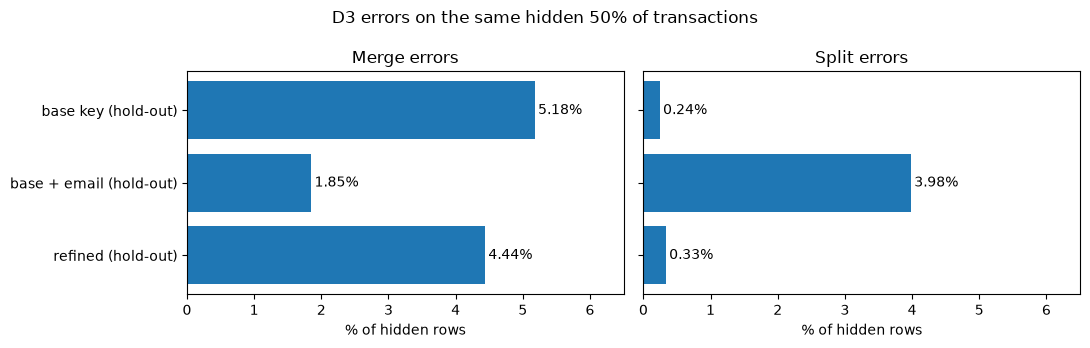

In [9]:
# plot the hold-out D3 errors
plot_rows = holdout_results.drop("refined (in-sample)")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)

axes[0].barh(plot_rows.index, plot_rows["merge errors %"])
axes[0].set_title("Merge errors")
axes[0].set_xlabel("% of hidden rows")

axes[1].barh(plot_rows.index, plot_rows["split errors %"])
axes[1].set_title("Split errors")
axes[1].set_xlabel("% of hidden rows")

for ax, col in zip(axes, ["merge errors %", "split errors %"]):
    for i, value in enumerate(plot_rows[col]):
        ax.text(value + 0.05, i, f"{value:.2f}%", va="center")
    ax.set_xlim(0, 6.5)

axes[0].invert_yaxis()
plt.suptitle("D3 errors on the same hidden 50% of transactions")
plt.tight_layout()
plt.show()

**Takeaway**
- The refinement splits 4,526 of the 217,020 base keys, giving 222,572 card IDs. Most base groups remain the same

- In the hold-out check, merge errors drop from 5.18% to 4.44% while split errors only go from 0.24% to 0.33%. So it separates some merged cards without breaking up real ones. The in-sample merge rate (1.38%) is too optimistic as we mentioned above, while the hold-out is too pessimistic since it hides `D3` from half of the transactions that actually have it (the final `card_id` uses `D3` wherever it is available). So for transactions with `D3`, the real merge rate should be somewhere between 1.38% and 4.44%. Transactions without `D3` (about 44% of all transactions) cannot be checked, so we do not know how accurate the key is for them

- The email key has fewer merge errors (1.85%) on the hidden rows, but its split errors are much higher (3.98%), which is the same problem as in Section 5

- Compared with its random control, the refined key has lower D4n/D10n/D15n spreads (e.g. D15n 19.96% vs 21.81%), fewer email conflicts and slightly fewer mixed-label keys, while the random split is actually slightly worse than the base key. Although the improvement is modest, this shows that the improvement from base -> refined is not only due to the smaller keys, but also because the refinement separates the right transactions

- The email key also beats its random control by a lot (e.g. D15n 15.32% vs 20.80%, mixed labels 2.26% vs 3.33%), so email does separate meaningful groups. But since `D3` shows that many of these groups belong to the same card, the card + email groups look more like different accounts or users on the same card (e.g. a fraudster using their own email on a stolen card) than different cards. We could possibly try email as a separate feature later (e.g. first time an email is used on a card), but not as the card ID

**Final decision**: use the refined `card_id` as the main card ID (`card_id_base` is still saved so results can be compared with the simpler key)

## 7. Check for leakage
We check that adding later transactions does not change earlier card IDs, by rebuilding the IDs using only the earliest 70% of transactions and comparing them with the IDs from the full dataset => if the IDs stay the same, there is no leakage

In [10]:
# rebuild the IDs using only the first 70% of the timeline
cutoff = ieee["TransactionDT"].quantile(0.7)
early = ieee[ieee["TransactionDT"] <= cutoff]

early_ids = chain_card_ids(early)
full_ids = ieee.loc[early.index, "card_id"]

same = early_ids.fillna("none").equals(full_ids.fillna("none"))

print("early transactions:", len(early))
print("same IDs as the full data:", same)

early transactions: 413378
same IDs as the full data: True


**Takeaway**
- All 413,378 transactions in the first 70% of the timeline get exactly the same ID whether or not the later transactions are included, so the card ID does not depend on future data and there is no leakage

## 8. Check card profiles and fraud history
1. We check how many transactions each reconstructed card has and how many cards appear each day. This shows how much history is available and helps us choose k for card-level Precision@k

2. We also check how often fraud happens after an earlier fraud under the same card ID, and compare this across the `card1 + addr1`, base and refined keys. According to the competition host, a transaction with a reported chargeback is labelled fraud, and later transactions linked to it by the same user account, email address or billing address are labelled fraud too (the card number used for fraud is always blacklisted) ([Data Description thread](https://www.kaggle.com/c/ieee-fraud-detection/discussion/101203#588953)) => fraud labels can spread to a card's later transactions, which card-history features could pick up as a shortcut

In [11]:
# 1. Transactions per card

cards = ieee.dropna(subset=["card_id"])
txns_per_card = cards.groupby("card_id").size()

print("number of cards:", len(txns_per_card))
print("rows with a card ID:", round(ieee["card_id"].notna().mean() * 100, 2), "%")
print("median transactions per card:", txns_per_card.median())
print("mean transactions per card:", round(txns_per_card.mean(), 1))

# group the cards by their number of transactions
size_group = pd.cut(txns_per_card, [0, 1, 2, 5, 10, 50, np.inf], labels=["1", "2", "3-5", "6-10", "11-50", ">50"])

card_sizes = pd.DataFrame({
    "cards": size_group.value_counts().sort_index(),
    "% of transactions": txns_per_card.groupby(size_group, observed=False).sum() / len(cards) * 100
})
display(card_sizes)

# transactions and distinct cards per day
per_day = cards.groupby("day").agg(transactions=("card_id", "size"), cards=("card_id", "nunique"))
display(per_day.describe().loc[["mean", "50%", "min", "max"]])

number of cards: 222572
rows with a card ID: 99.79 %
median transactions per card: 1.0
mean transactions per card: 2.6


,cards,% of transactions
1,128013,21.723961
2,37067,12.580629
3-5,34816,21.860740
6-10,14770,18.620465
11-50,7717,22.548878
>50,189,2.665327


,transactions,cards
mean,3237.752747,2384.604396
50%,3045.000000,2281.500000
min,2048.000000,1571.000000
max,6852.000000,4259.000000


In [12]:
# 2. Check fraud after an earlier fraud

keys_to_check = {
    "card1 + addr1": card1_addr1_key,
    "base key": ieee["card_id_base"],
    "refined card_id": ieee["card_id"]
}

propagation = {}

for name, key in keys_to_check.items():
    rows = ieee.assign(key=key).dropna(subset=["key"])

    # number of earlier fraud transactions on the same key (rows are already in time order)
    earlier_frauds = rows.groupby("key")["isFraud"].cumsum() - rows["isFraud"]
    flagged = earlier_frauds > 0

    per_key = rows.groupby("key")["isFraud"].agg(["size", "sum"])
    fraud_keys = per_key[per_key["sum"] > 0]

    propagation[name] = {
        "overall fraud rate %": rows["isFraud"].mean() * 100,
        "fraud rate after an earlier fraud %": rows.loc[flagged, "isFraud"].mean() * 100,
        "fraud rate with no earlier fraud %": rows.loc[~flagged, "isFraud"].mean() * 100,
        "fraud txns on an already flagged key %": flagged[rows["isFraud"] == 1].mean() * 100,
        "keys with any fraud %": len(fraud_keys) / len(per_key) * 100,
        "fraud keys where every txn is fraud %": (fraud_keys["sum"] == fraud_keys["size"]).mean() * 100
    }

display(pd.DataFrame(propagation))

,card1 + addr1,base key,refined card_id
overall fraud rate %,2.462112,3.498730,3.498730
fraud rate after an earlier fraud %,4.942785,44.663412,46.904861
fraud rate with no earlier fraud %,0.938647,1.440459,1.456661
fraud txns on an already flagged key %,76.381365,60.789640,60.236698
keys with any fraud %,8.131944,3.725002,3.683302
fraud keys where every txn is fraud %,22.477064,61.615537,62.649427


**Takeaway**
- There are 222,572 cards covering 99.79% of transactions (the rest have no `D1`). Most cards are small as the median card only has 1 transaction and 128,013 cards appear only once. But these single-transaction cards only make up 22% of transactions, while cards with 3 or more transactions make up around 65.7%. So most transactions do have some card history

- On average there are around 3,200 transactions and 2,400 distinct cards per day (1,571 to 4,259) => can use this for choosing k in card-level Precision@k

- Fraud is much more common after an earlier fraud in the same group. After a card's first fraud, 46.9% of its later transactions are also fraud, compared with 3.5% overall and 1.5% for transactions on cards with no earlier fraud. 60% of all fraud transactions are on a card that already had a fraud, and 63% of the cards with any fraud are fraud on every transaction

- The `card1 + addr1` key has an even higher "already flagged" share (76%) because one key contains many cards, so another card's fraud counts as an earlier fraud. This is another reason not to use it as the card ID

## 9. Save card IDs
We save one row per `TransactionID` with both keys to `data/interim/ieee_card_id.csv`. This file is built from the raw data, so it should not be committed

In [13]:
INTERIM_DIR.mkdir(parents=True, exist_ok=True)

card_ids = ieee[["TransactionID", "card_id"]].sort_values("TransactionID")
card_ids.to_csv(INTERIM_DIR / "ieee_card_id.csv", index=False)

print("saved", len(card_ids), "rows")
print("unique TransactionIDs:", card_ids["TransactionID"].is_unique)
card_ids.head()

saved 590540 rows
unique TransactionIDs: True


,TransactionID,card_id
0,2987000,13926_315_-13#0
1,2987001,2755_325_1#0
2,2987002,4663_330_1#0
3,2987003,18132_476_-111#0
4,2987004,4497_420_1#0


## 10. Limitations
- **No true card number**: since the dataset has no card numbers, we can only check the keys indirectly (`D3`, the other D columns and labels). `D3` is missing for about 44% of transactions (almost all `H` and `R`, and a third of `W`), so these transactions cannot be checked. `H` and `R` are basically unchecked, and for them the refined key is the same as the base key

- **Card vs account**: `D1` might count from when the account was opened rather than when the physical card was first used, so a replaced card with the same `card1` and `addr1` may keep the same ID, and 2 cards opened on the same day may share one

- **Same-day cards**: large `card1 + addr1` groups can contain several cards first used on the same day. D3 chaining can only separate them when their transactions are spaced in a way that `D3` can tell apart

- **Missing values**: transactions without `D1` (0.21%) get no card ID and therefore no card history. Transactions without `addr1` (11%, mostly `ProductCD = C`) still get an ID, with `NA` used in place of the address (e.g. `4497_NA_88`). This keeps them in the card history, but different cards with the same `card1` and first-use day and no recorded address could be grouped together